# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2026-01-09"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p8"
subproj <- "AVGUSTINOVA_02_03"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "NRXN1"  "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.2

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- assay_ch

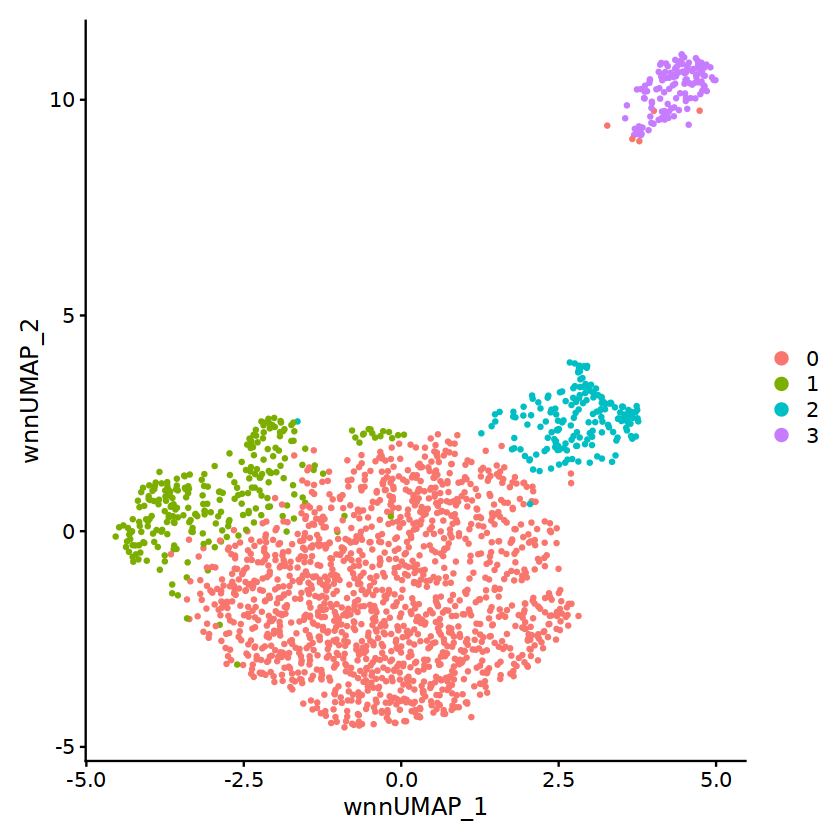

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

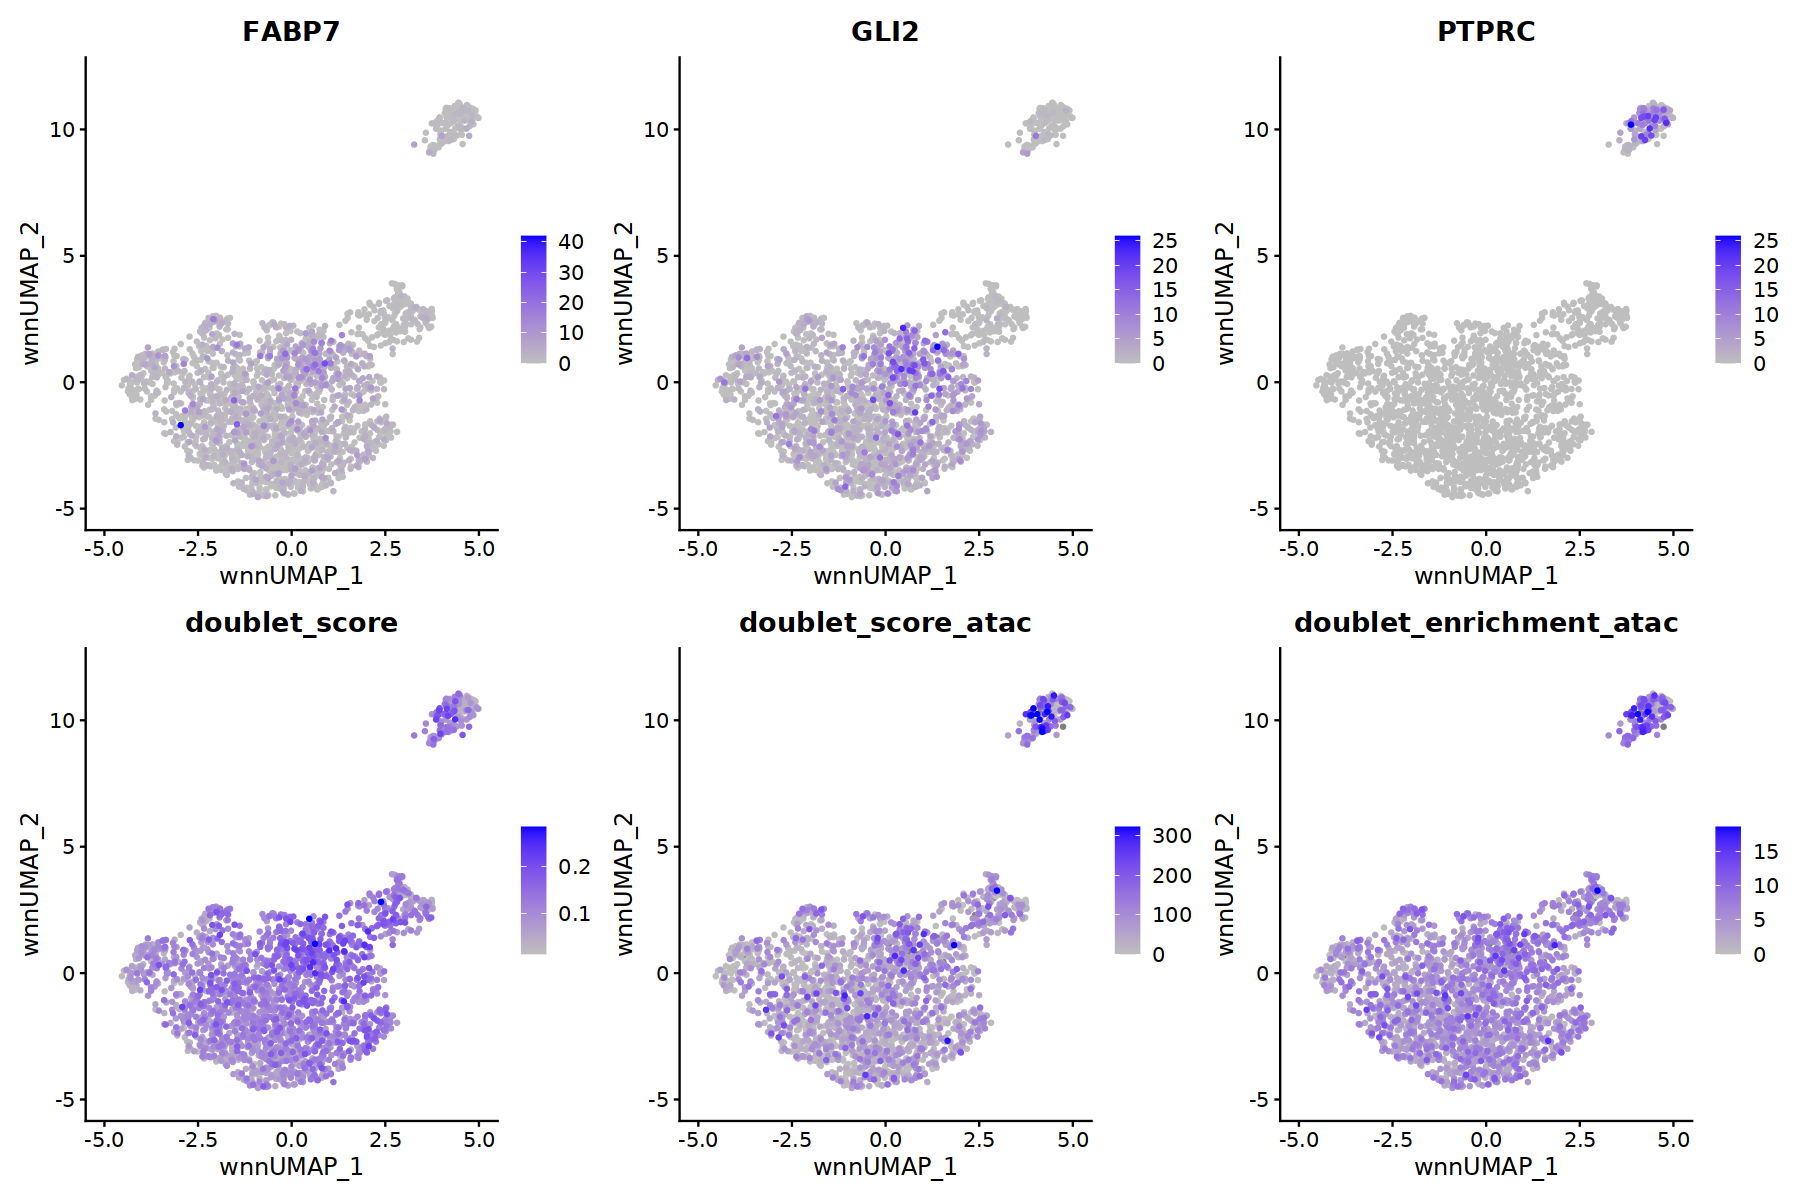

In [11]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("FABP7","GLI2","PTPRC",
                      "doublet_score","doublet_score_atac","doublet_enrichment_atac"), 
            ncol=3,cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

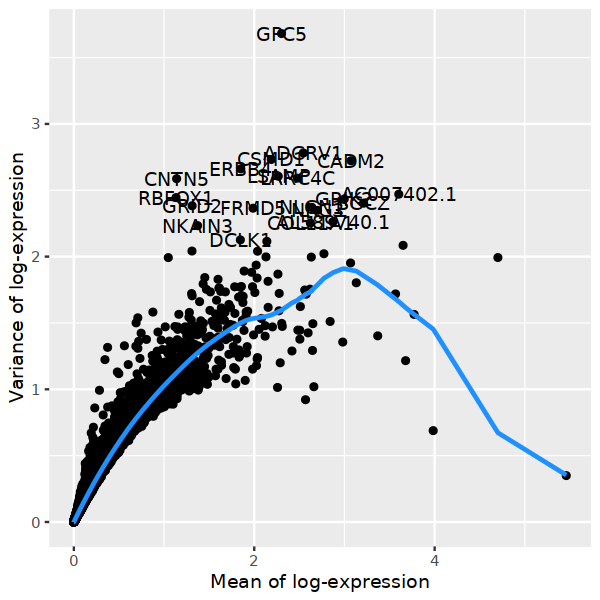

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 1633
[1] 1632


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  LRMDA, RGS1, PLXDC2, TBXAS1, DPYD, APBB1IP, ADAM28, ARHGAP15, LNCAROD, PTPRC 
	   DOCK8, DOCK2, FMN1, UBE2E2, ELMO1, MEF2C, RBM47, FYB1, AOAH, SAMSN1 
	   ARHGAP24, MS4A4E, MGAT4A, CD74, FKBP5, SAT1, HLA-DRB1, LPCAT2, CD163, USP53 
Negative:  AC007402.1, ADGRV1, LRRC4C, FRMD5, CSMD1, LSAMP, GPC5, ERBB4, NKAIN3, DCC 
	   AL357507.1, GRID2, CNTN5, RBFOX1, KIAA1217, DLGAP1, CTNNA2, PTCHD1-AS, AC092691.1, CDH8 
	   RELN, LRRTM4, UNC5D, LRP1B, DACH2, NRXN3, ADGRL3, PDE10A, ROBO1, C8orf34 
PC_ 2 
Positive:  PTPRD, MYT1L, LRRC7, UNC79, ATRNL1, CCSER1, NKAIN2, SYT1, SORBS2, CHL1 
	   ADGRL3, SYT14, KCNIP4, MDGA2, TENM2, DOK6, CDH13, RIMS1, PTPRT, DSCAM 
	   ERC2, GRID1, SHISA9, CDH18, PDE4D, ATP8A2, NELL1, CNTN1, CSMD2, GRM7 
Negative:  AL357507.1, AC007402.1, FRMD5, ADGRV1, GPC5, KIAA1217, MIR924HG, OBI1-AS1, PTCHD1-AS, AL390957.1 
	   RMDN2-AS1, FKBP5, TPRG1, LRMDA, ARHGAP15, RGS1, LYN, SRGN, DOCK8, CTSB 
	   RBM47, CALCR, ITPR2, PTPRC, FY

In [19]:
markers = c("FABP7", "GLI2","MEIS2", "GMP6A","PTPRC")

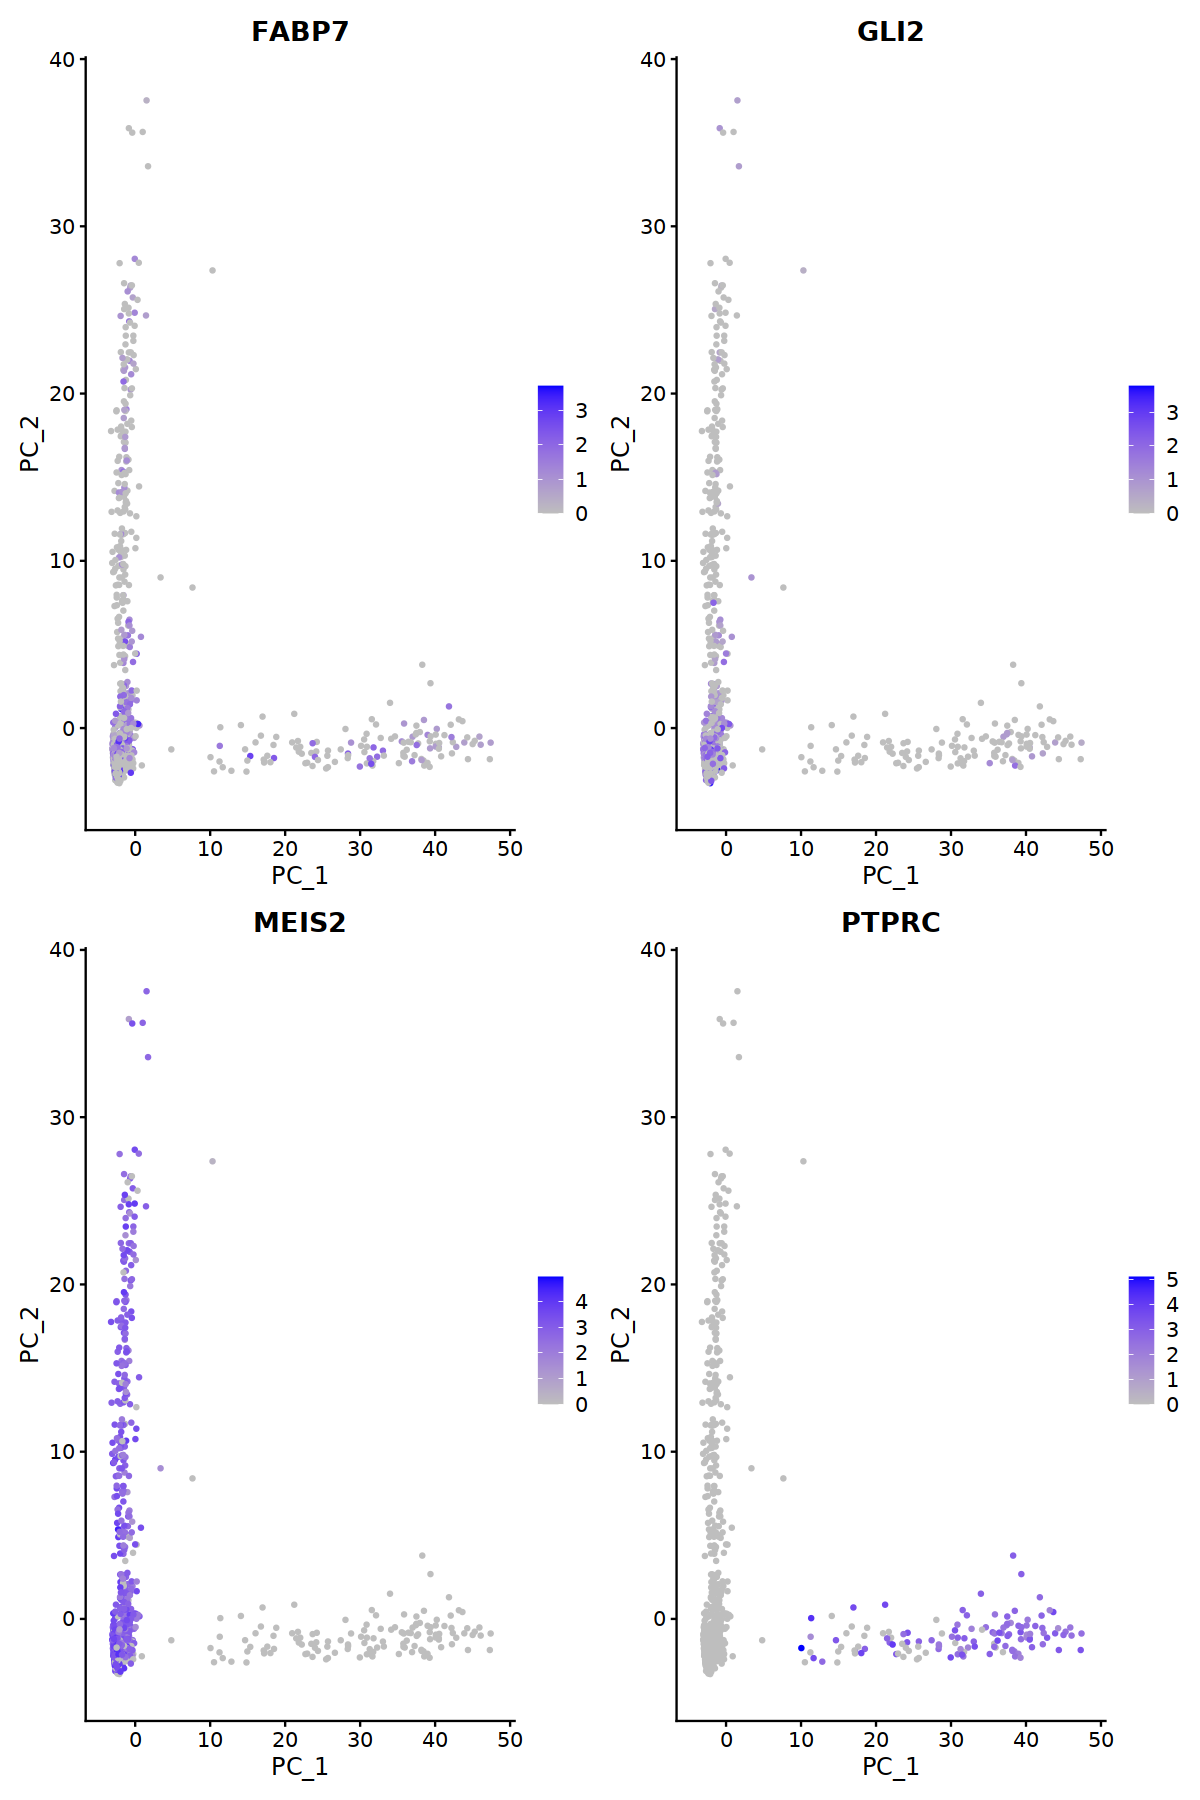

In [20]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "pca", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

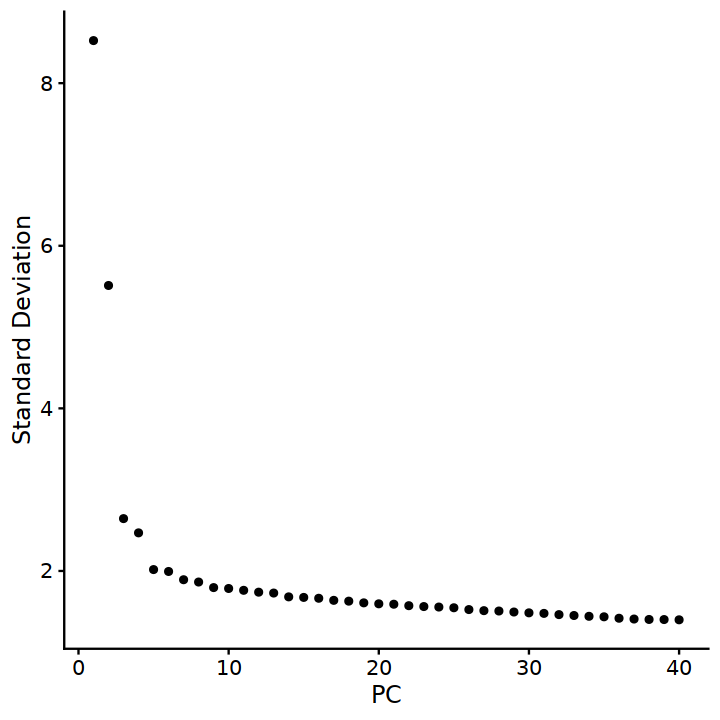

In [21]:
options(repr.plot.width = 6, repr.plot.height =6)
ElbowPlot(seurat_obj, n=40)

In [22]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


16:28:34 UMAP embedding parameters a = 0.9922 b = 1.112

16:28:34 Read 2014 rows and found 20 numeric columns

16:28:34 Using Annoy for neighbor search, n_neighbors = 30

16:28:34 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:28:35 Writing NN index file to temp file /scratch_tmp/51247936/RtmpfvZjTU/file2fd9040a2e64d

16:28:35 Searching Annoy index using 1 thread, search_k = 3000

16:28:35 Annoy recall = 100%

16:28:36 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:28:37 Initializing from normalized Laplacian + noise (using irlba)

16:28:37 Commencing optimization for 500 epochs, with 87130 positive edges

16:28:44 Optimization finished



In [23]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [24]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

16:28:49 UMAP embedding parameters a = 0.9922 b = 1.112

16:28:49 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

16:28:51 Initializing from normalized Laplacian + noise (using irlba)

16:28:51 Commencing optimization for 500 epochs, with 62002 positive edges

16:28:58 Optimization finished



In [25]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2014
Number of edges: 75209

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9556
Number of communities: 4
Elapsed time: 0 seconds


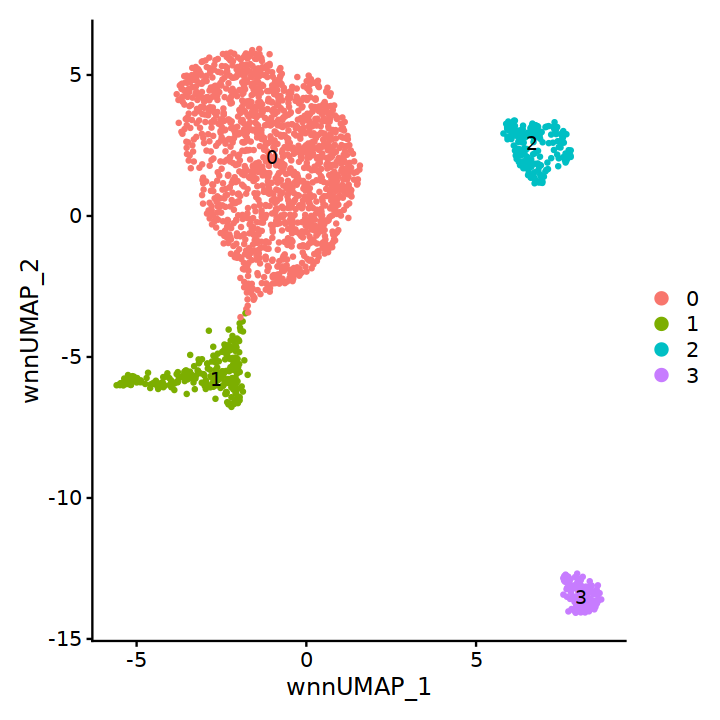

In [26]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

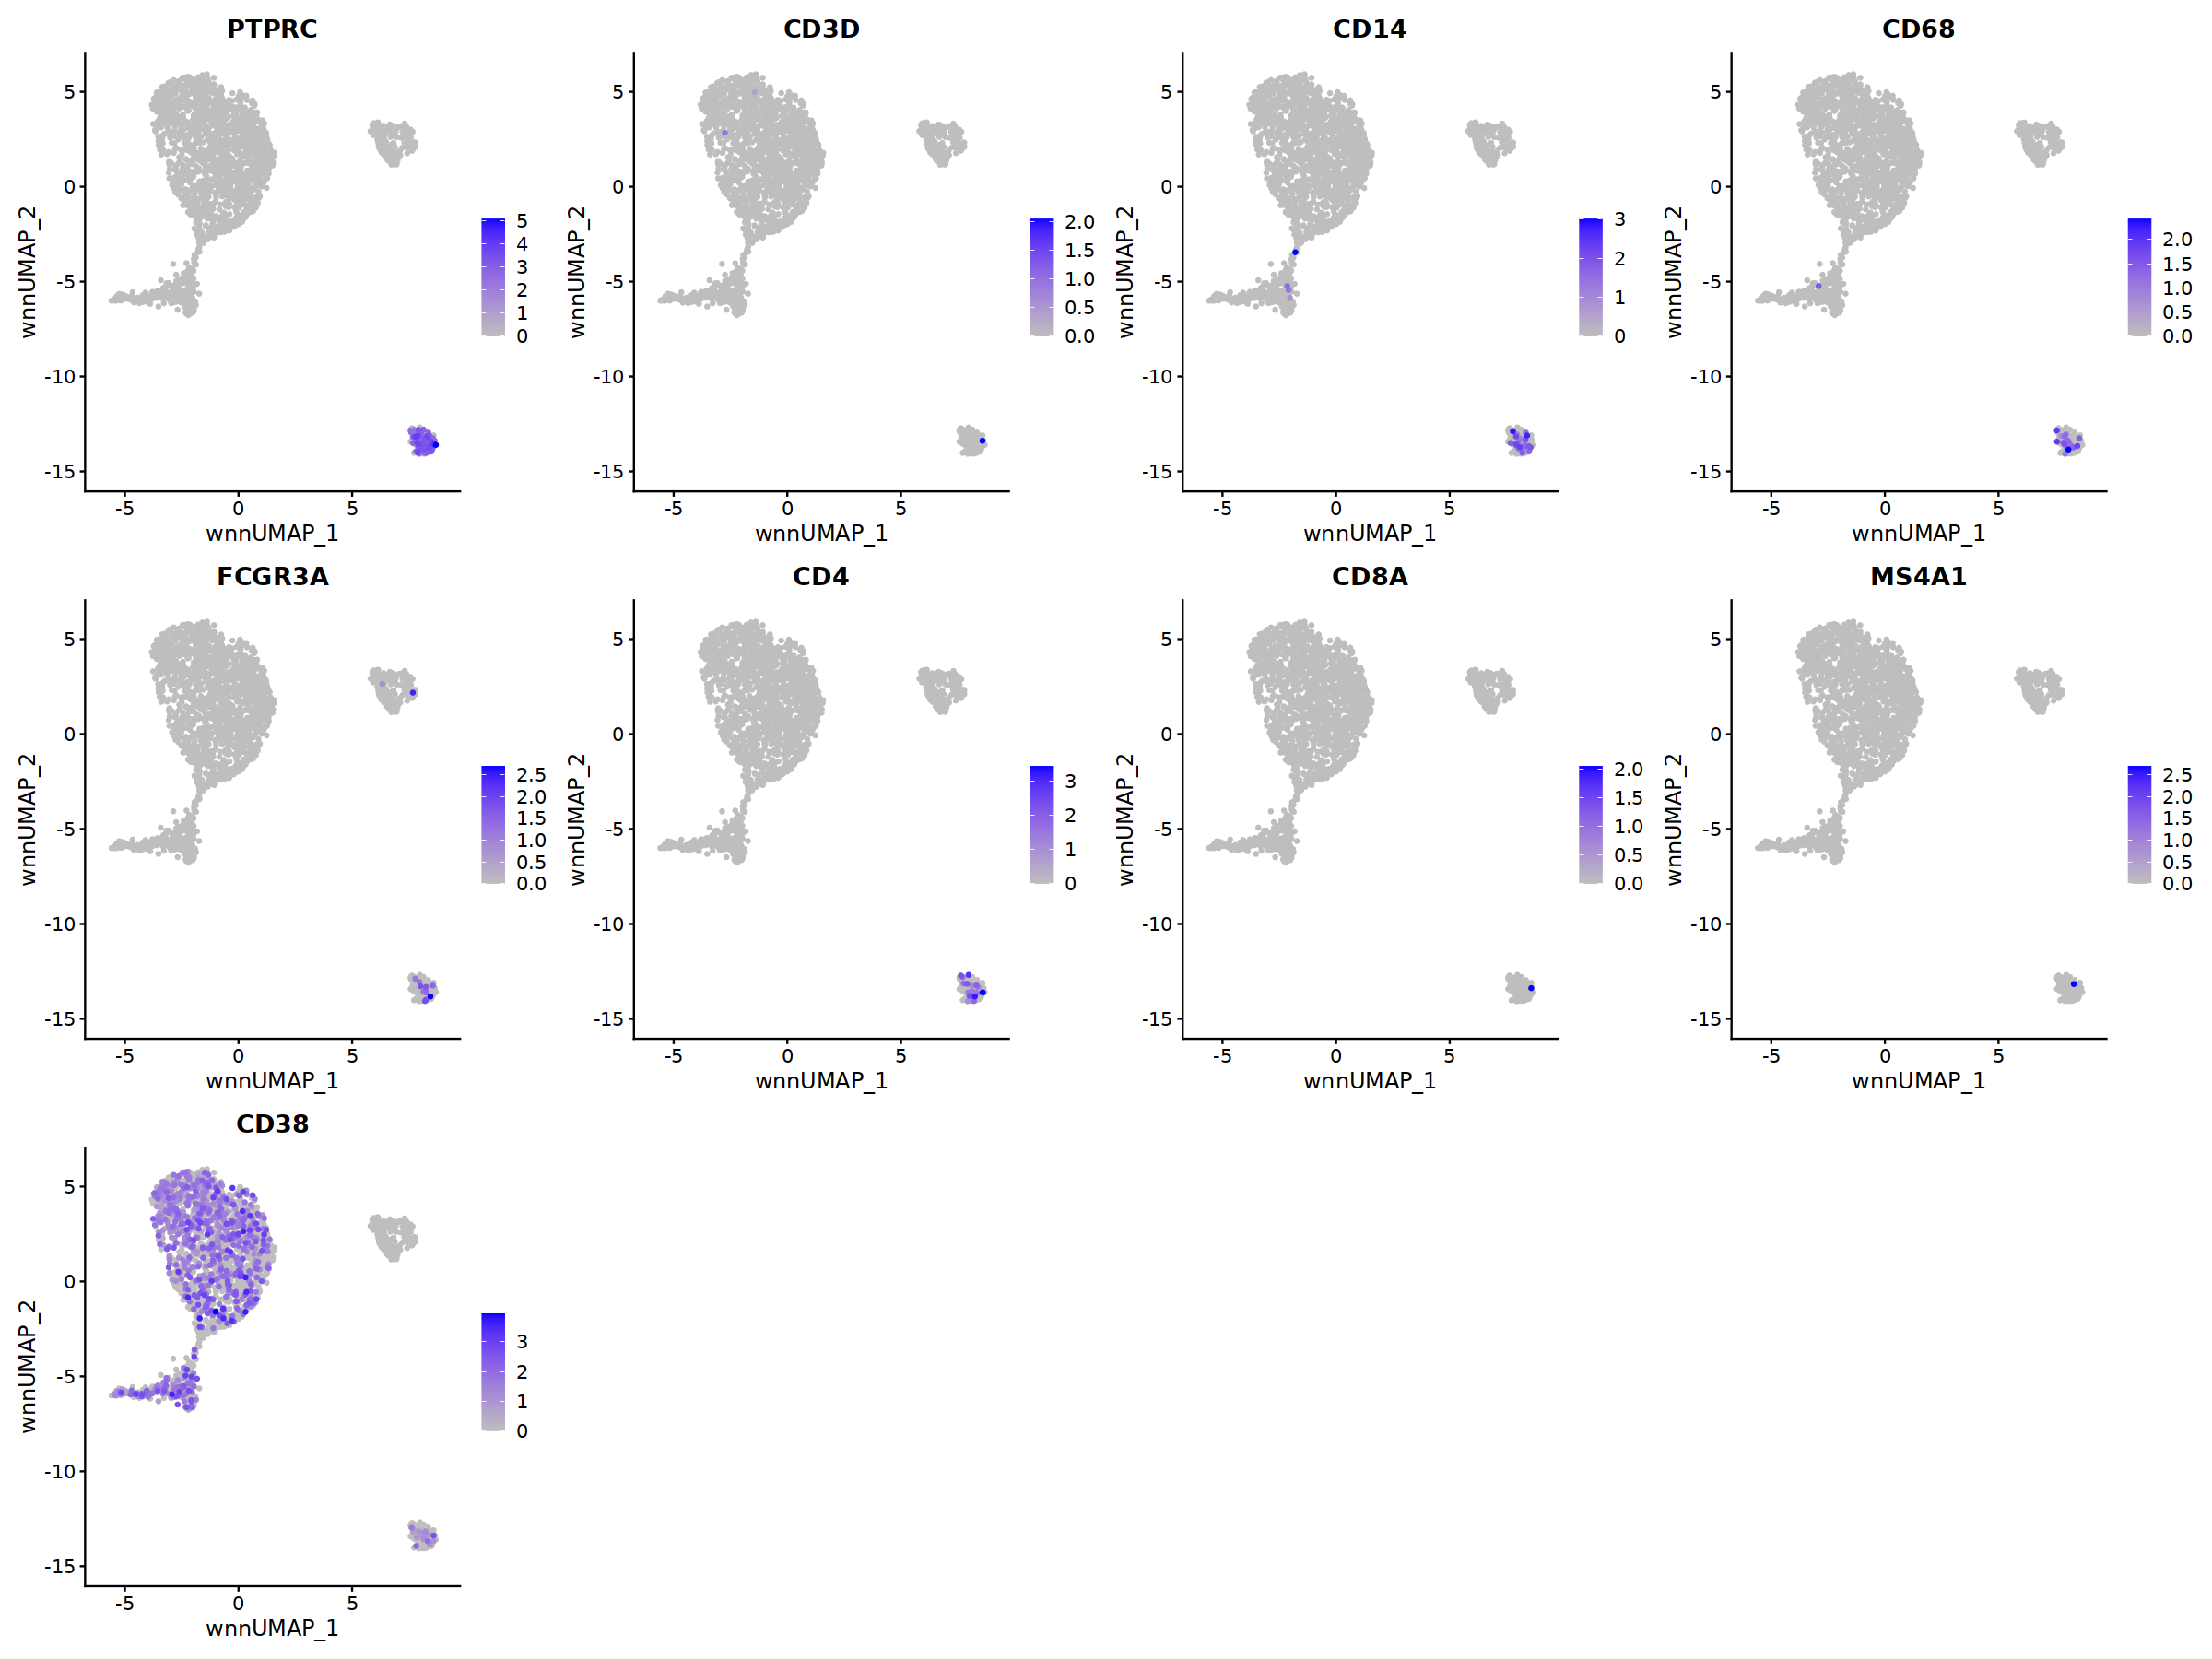

In [27]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

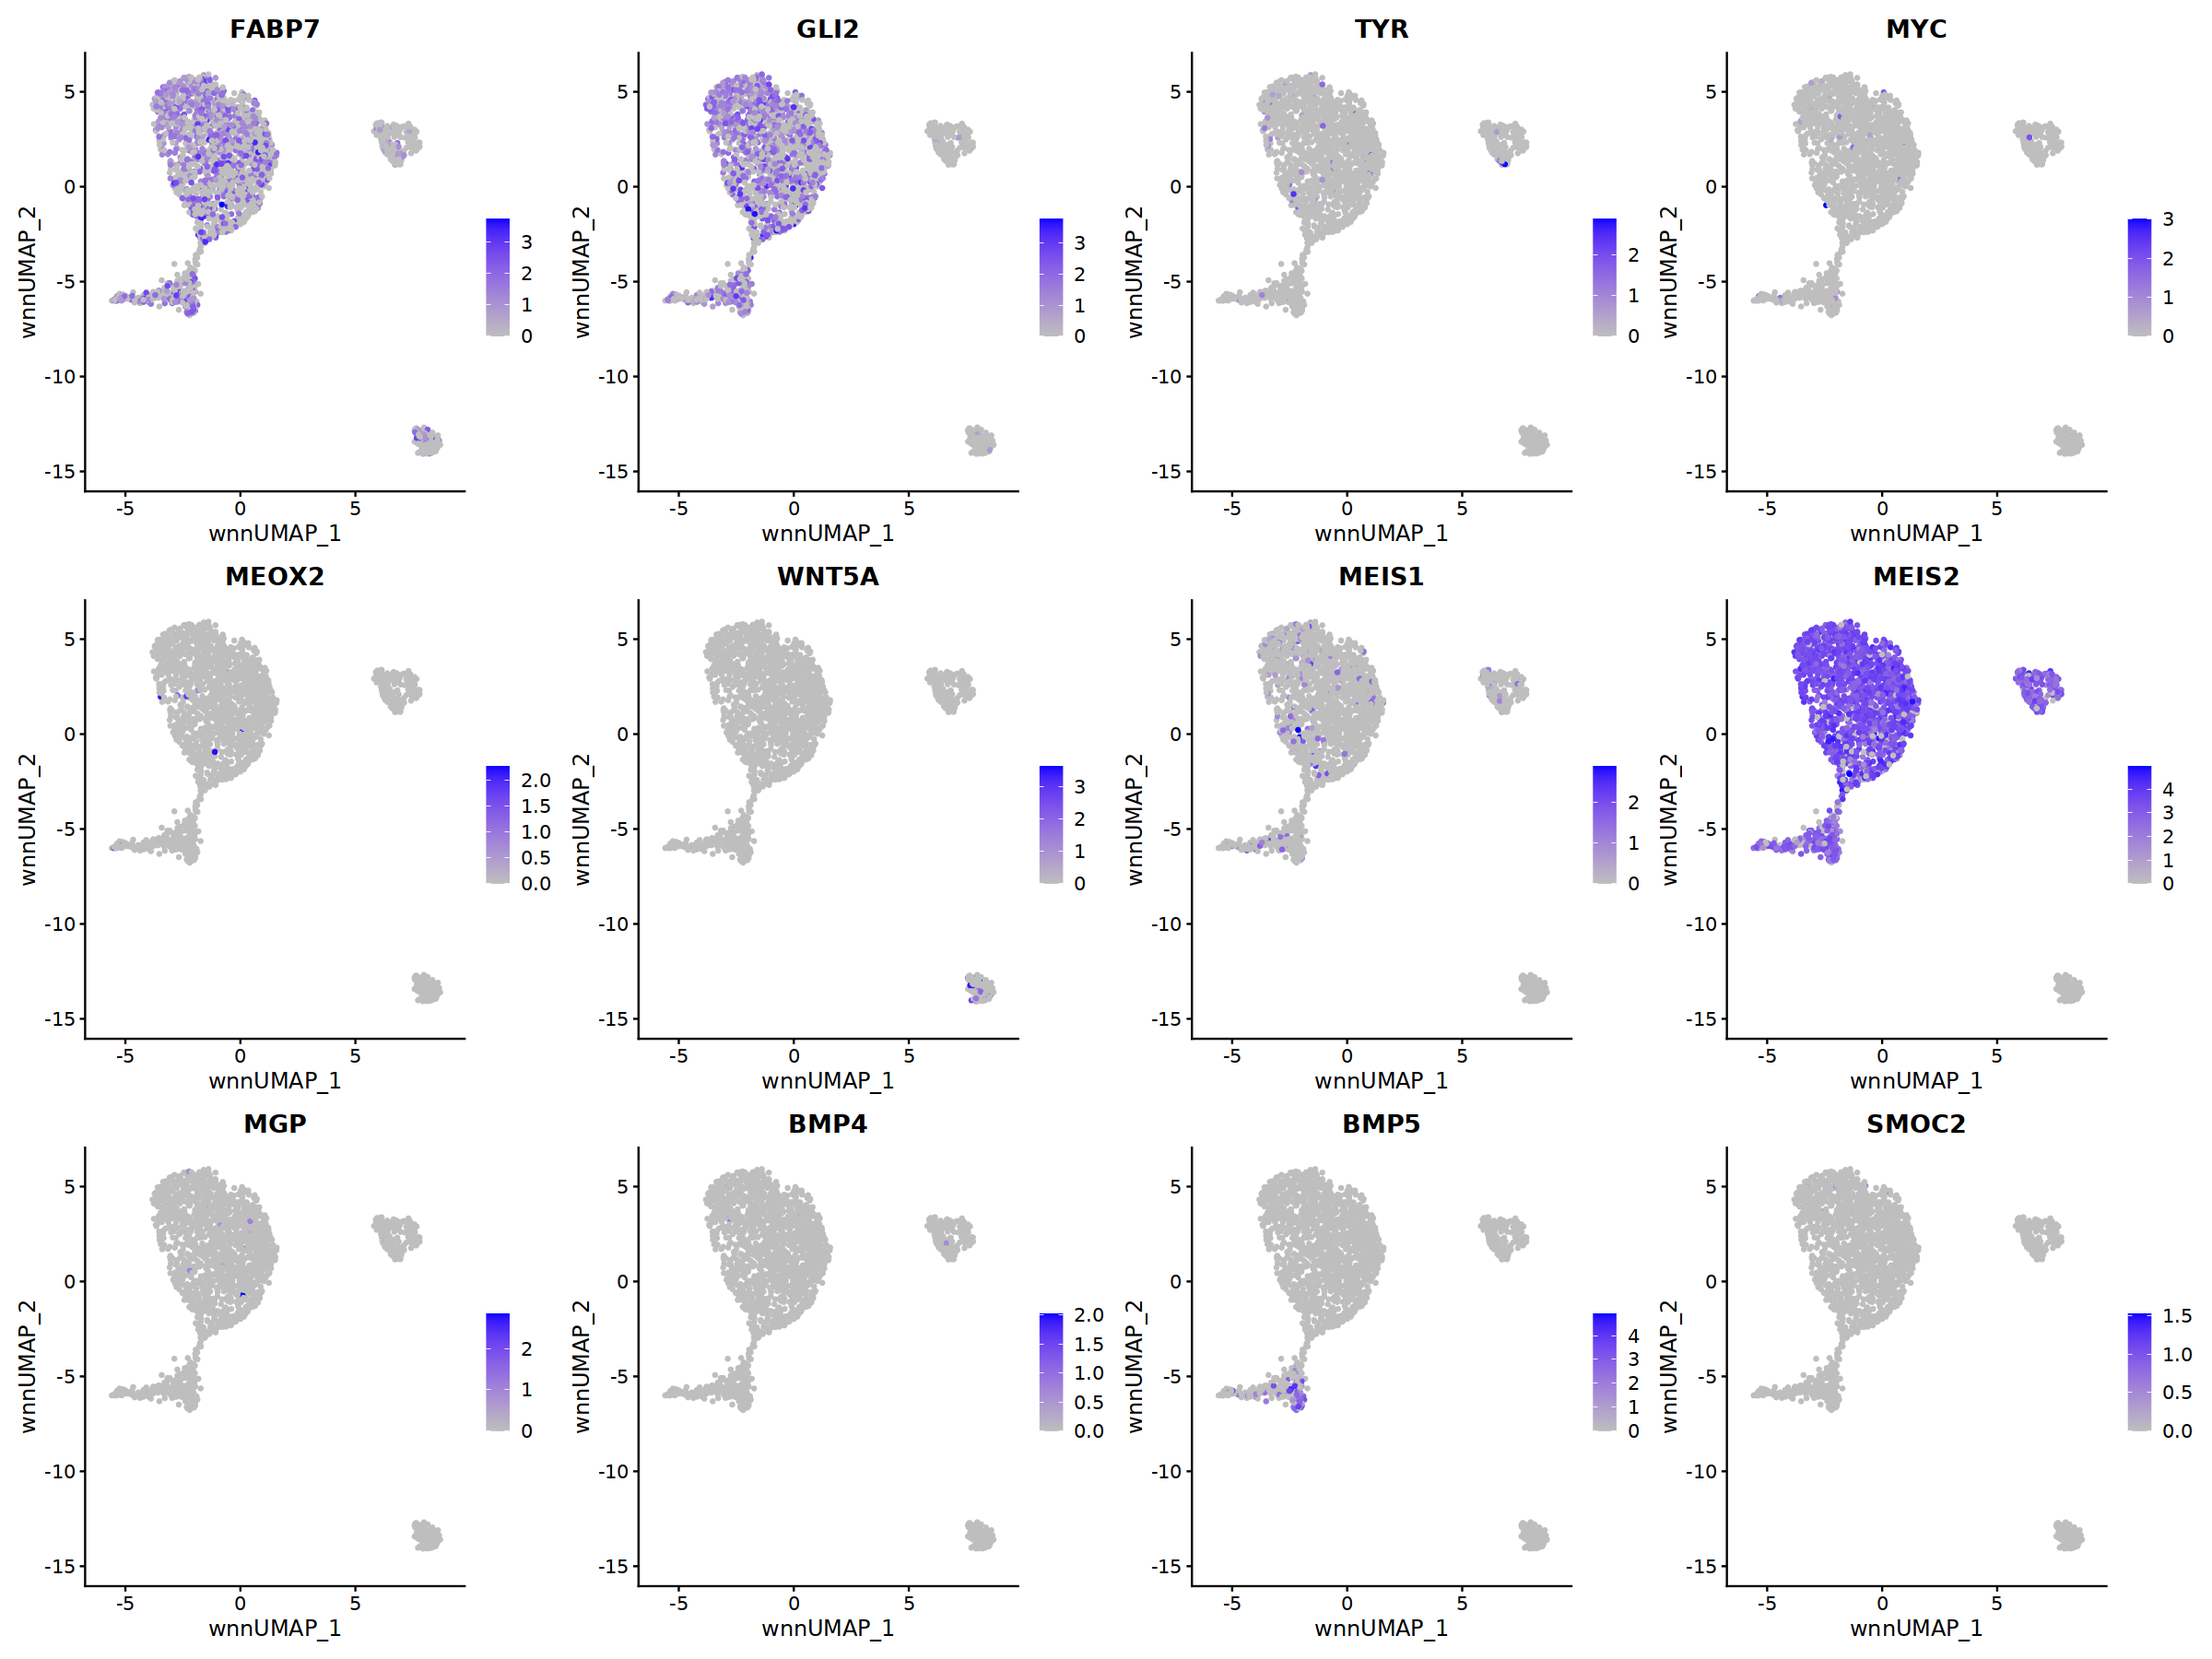

In [28]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

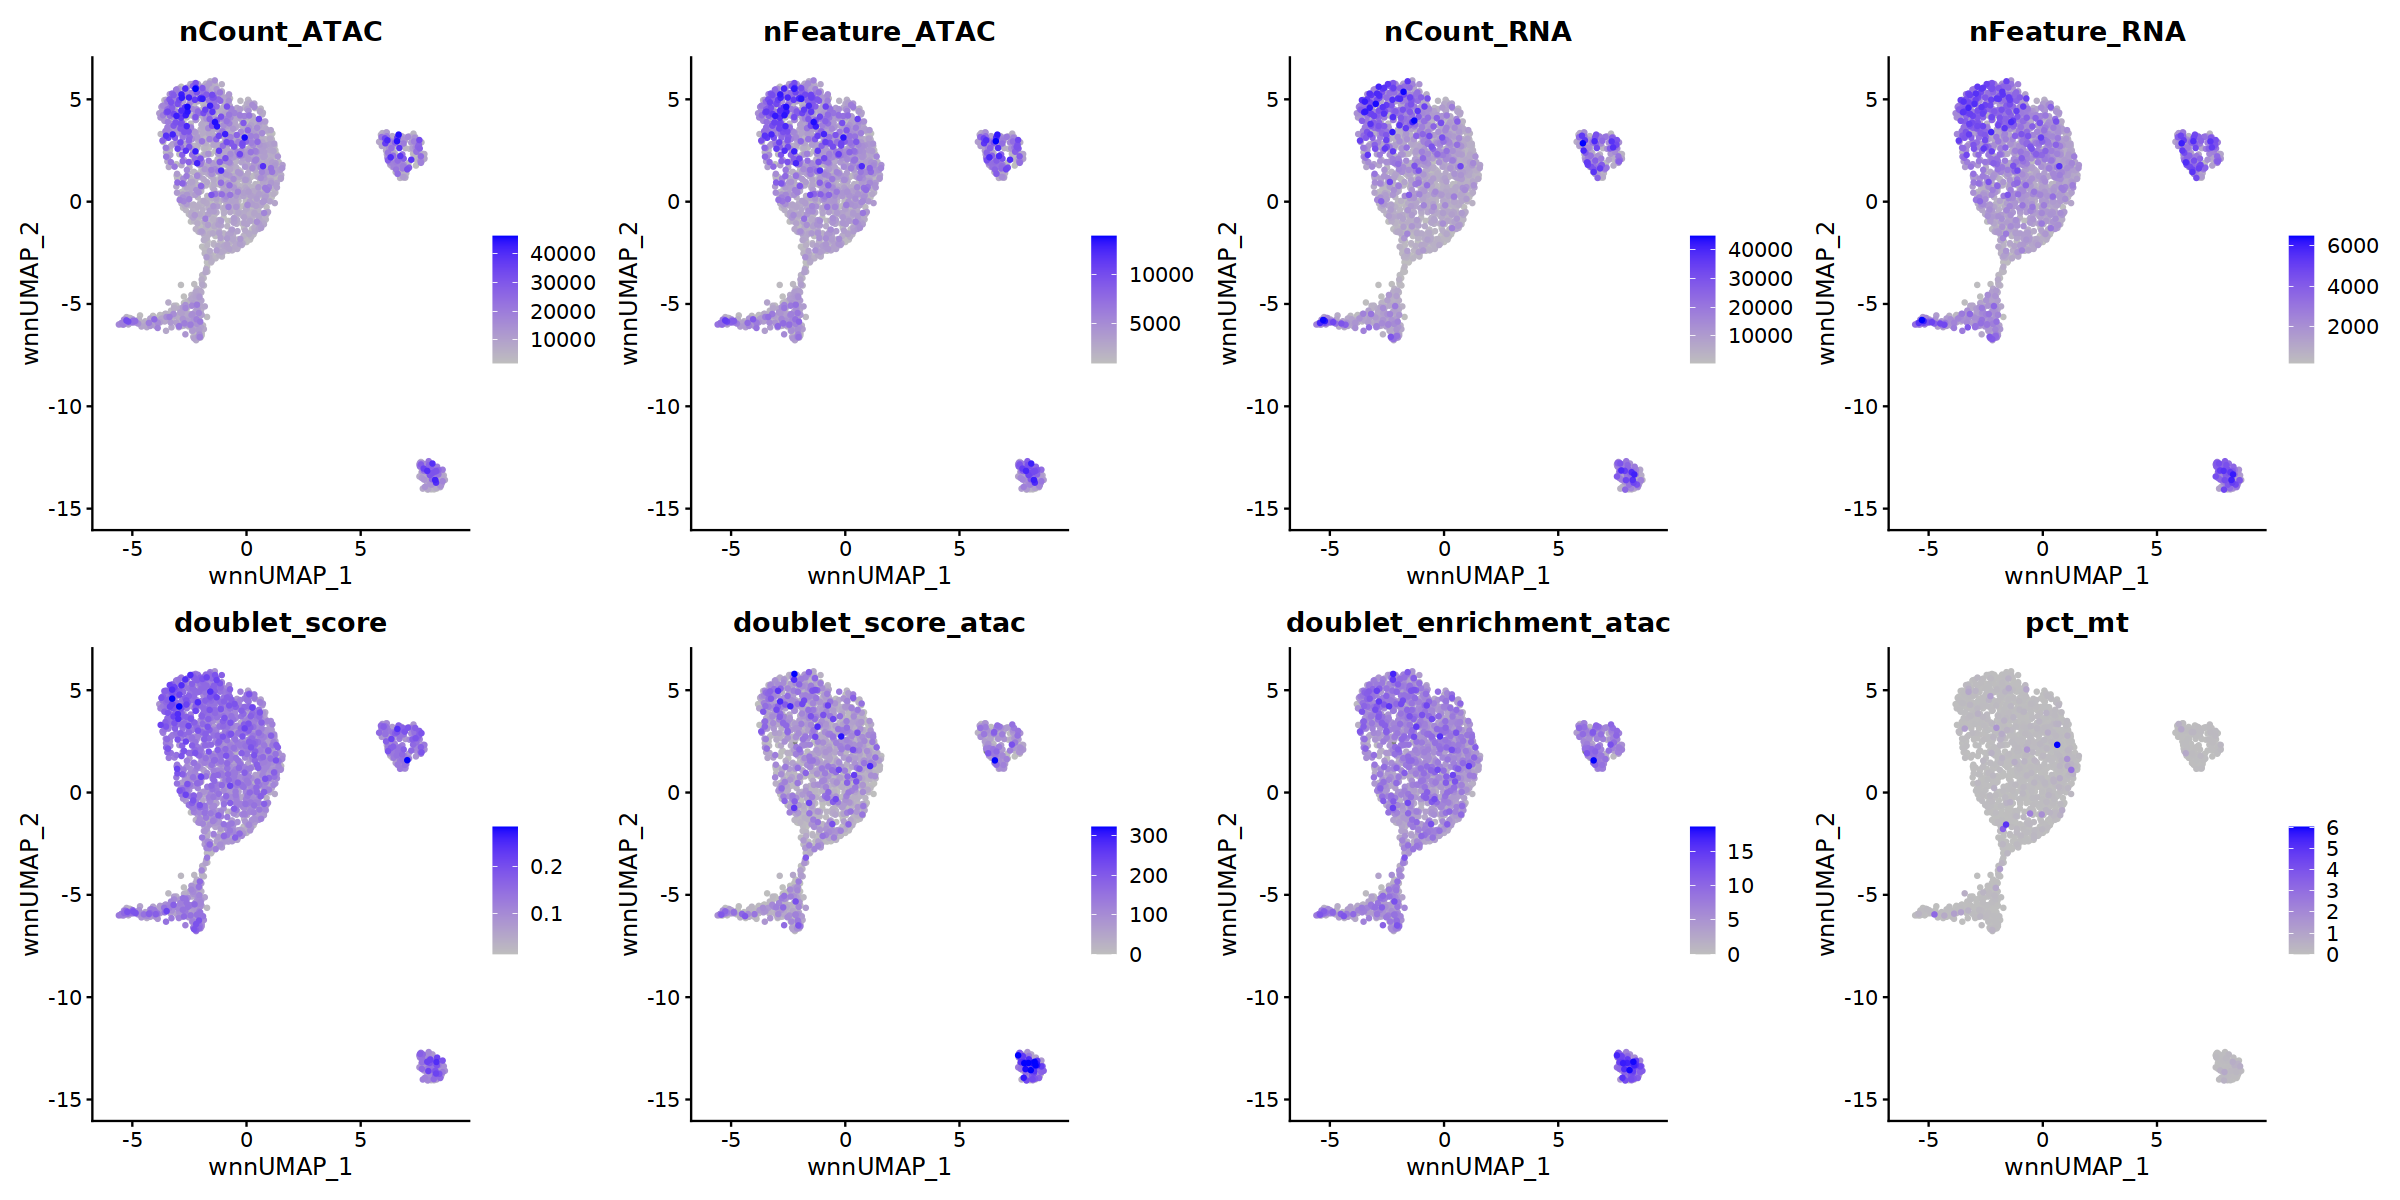

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

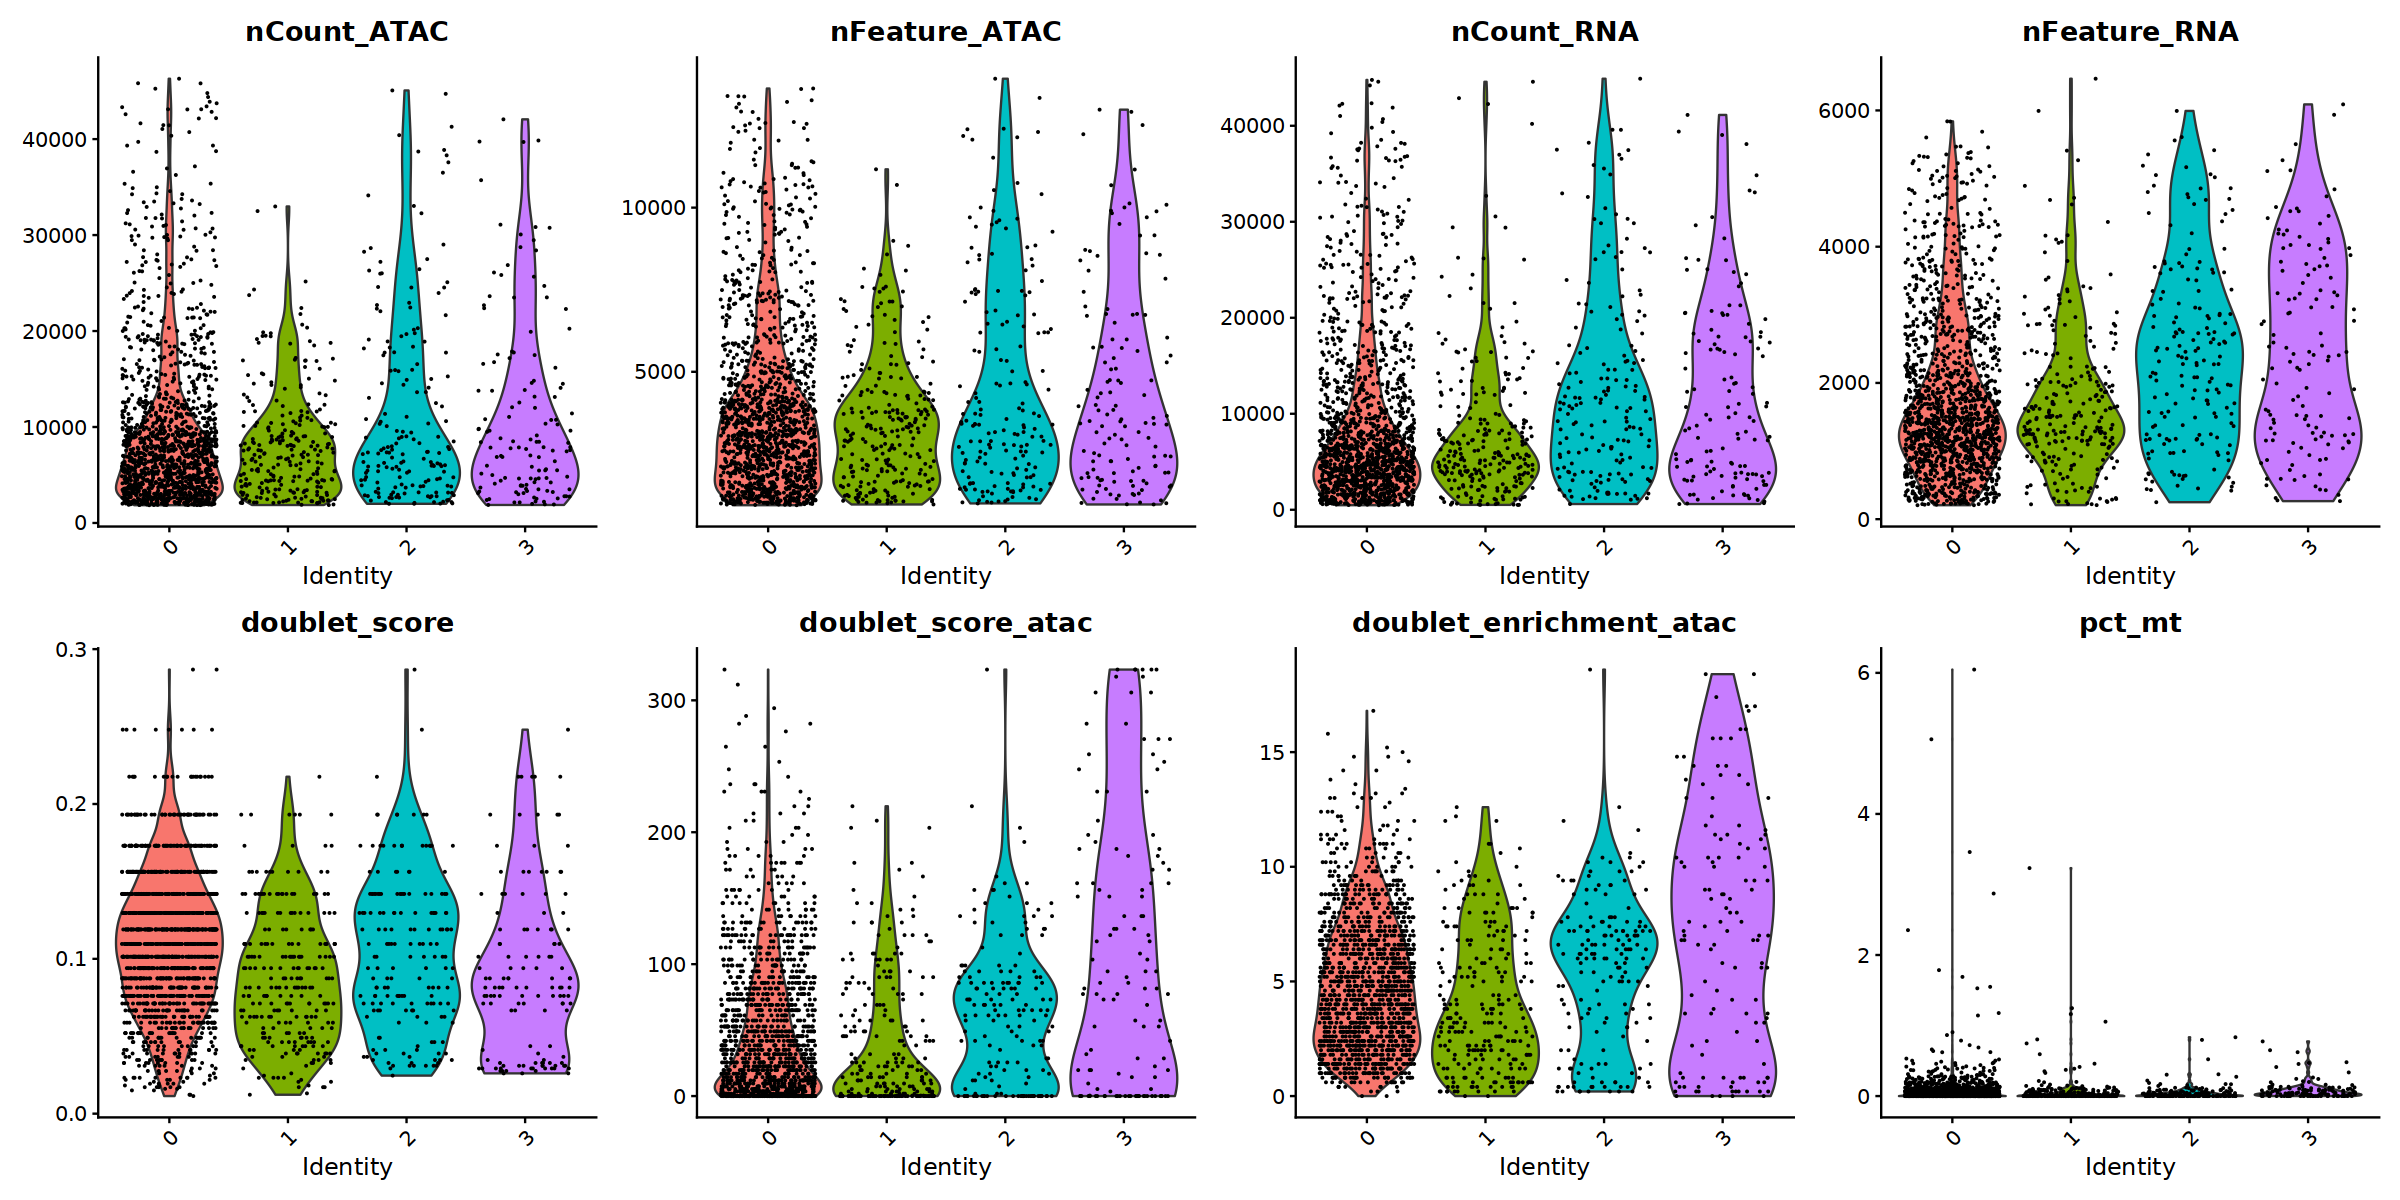

In [30]:
VlnPlot(seurat_obj,feature=qc_vars, ncol = 4)

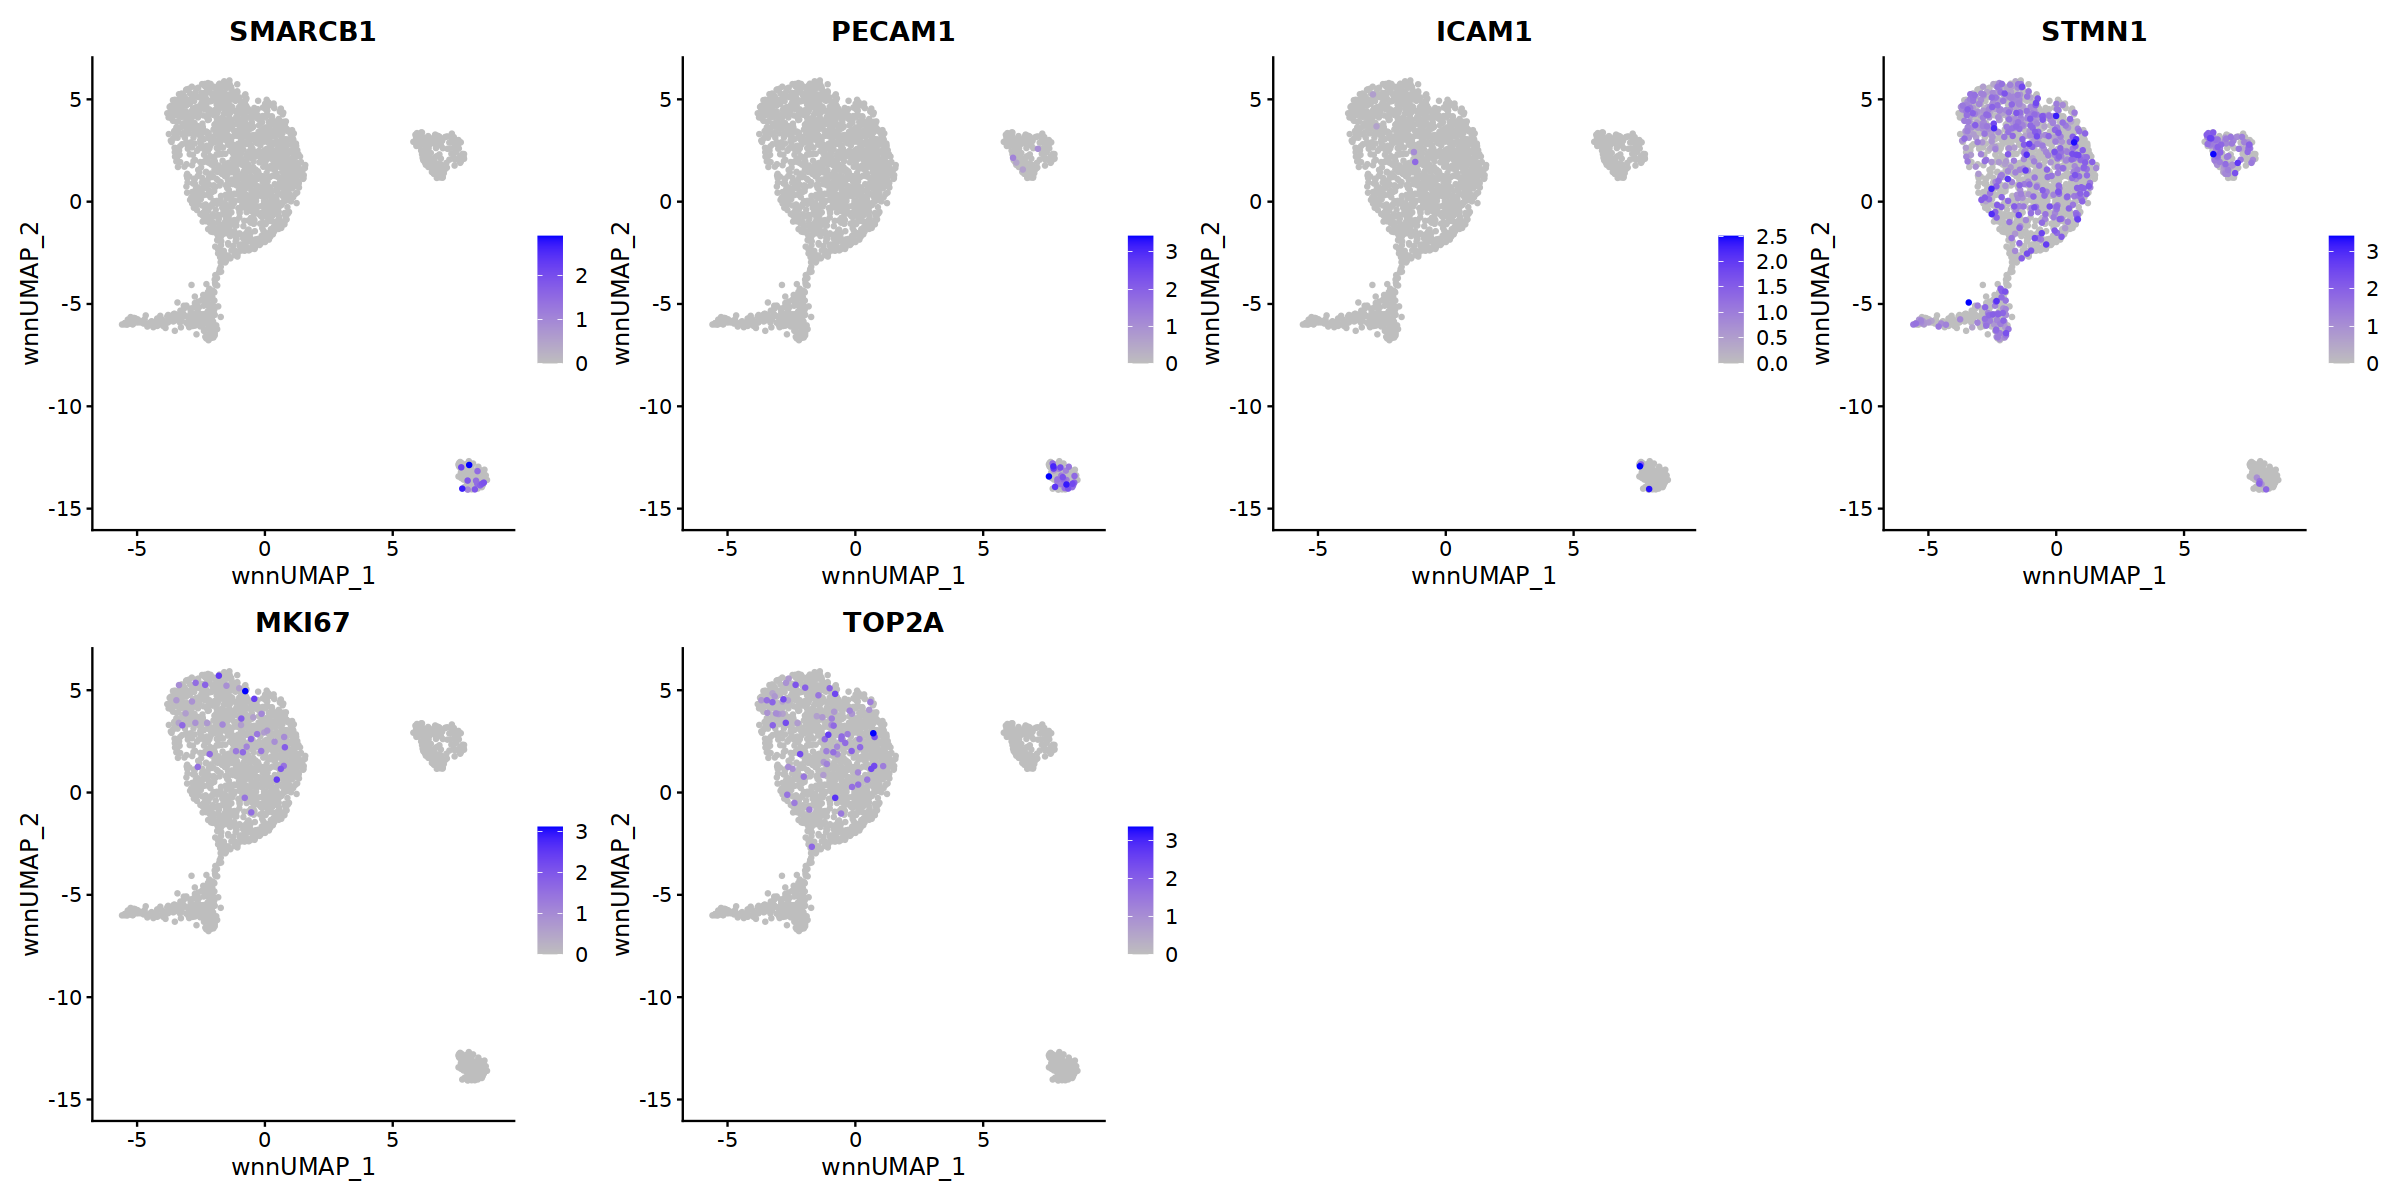

In [31]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [32]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3



In [33]:
rna.markers %>% 
  dplyr::filter(cluster == "3") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
PLXDC2,1.214462e-219,5.994338,0.924,0.060,3.389320e-215,3,PLXDC2
LRMDA,0.000000e+00,5.652054,0.924,0.001,0.000000e+00,3,LRMDA
SPP1,2.852246e-138,4.747397,0.466,0.013,7.960048e-134,3,SPP1
RGS1,0.000000e+00,4.675066,0.847,0.002,0.000000e+00,3,RGS1
FKBP5,1.474813e-118,4.530673,0.863,0.150,4.115907e-114,3,FKBP5
DOCK41,7.792131e-82,4.422694,0.939,0.408,2.174628e-77,3,DOCK4
DPYD,2.709984e-273,4.418226,0.878,0.025,7.563023e-269,3,DPYD
ARHGAP15,0.000000e+00,4.340342,0.771,0.002,0.000000e+00,3,ARHGAP15
MEF2C,2.222291e-204,4.192592,0.779,0.036,6.201969e-200,3,MEF2C


### Rename

In [34]:
rename_clusters <- c("0"="Tumor GPC5", "1"="Tumor BMP5",
                     "2"="Tumor ROBO1", "3"="Monocytes-Macrophages")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [35]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [36]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [37]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [38]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [39]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Immune

Calculating cluster Tumor



In [40]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

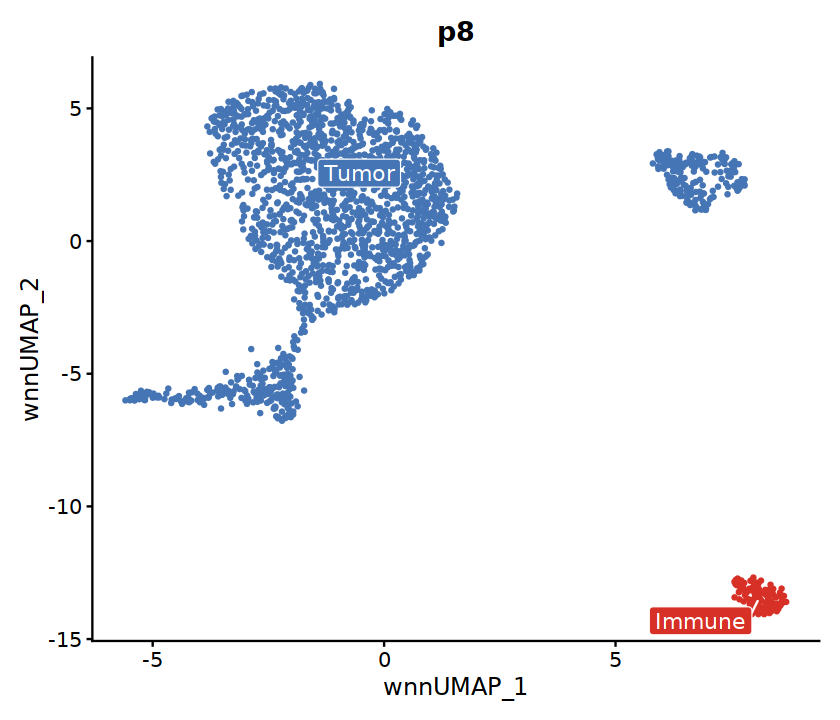

In [41]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [42]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [43]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [44]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

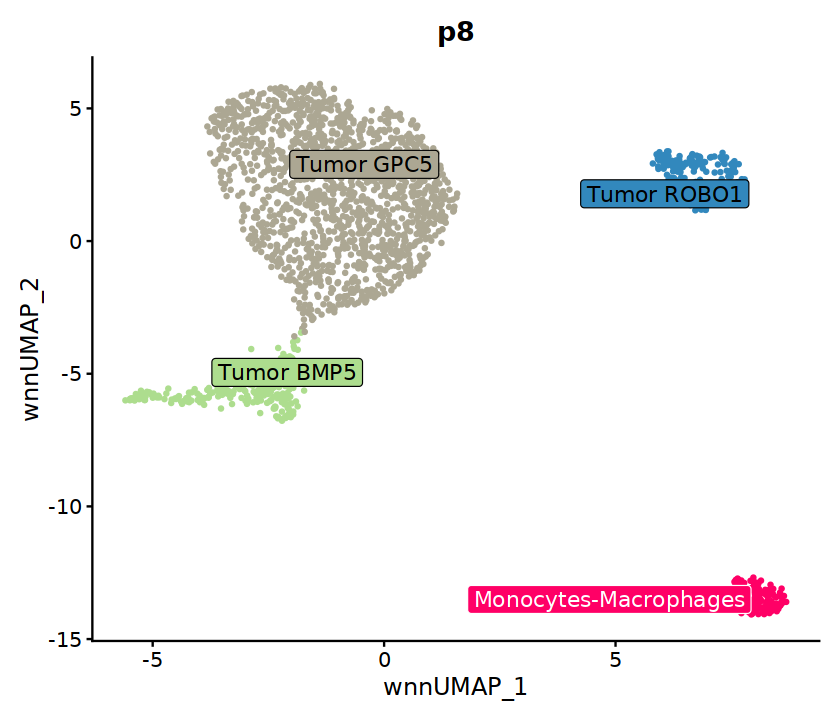

In [45]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [46]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

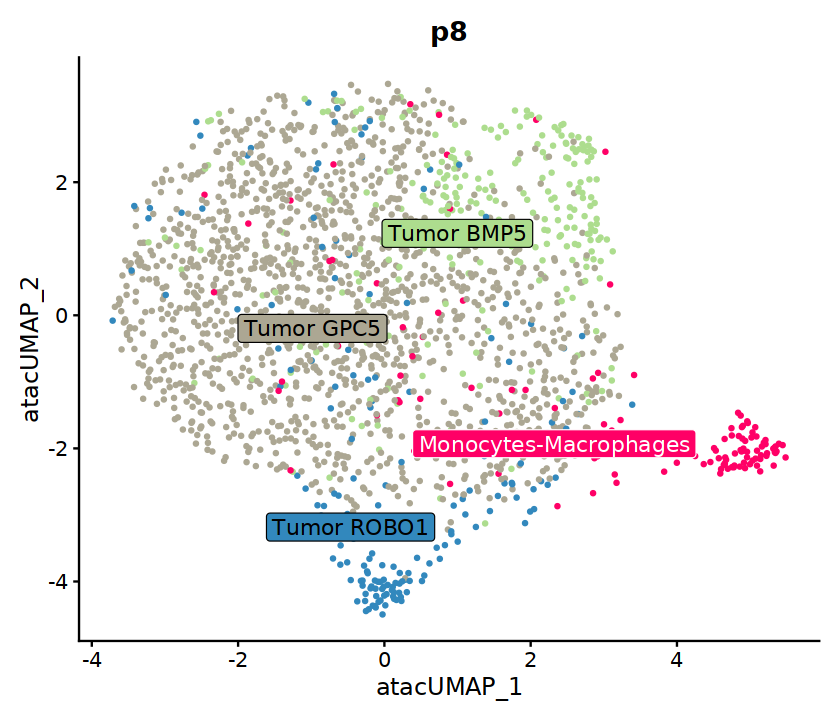

In [47]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [48]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

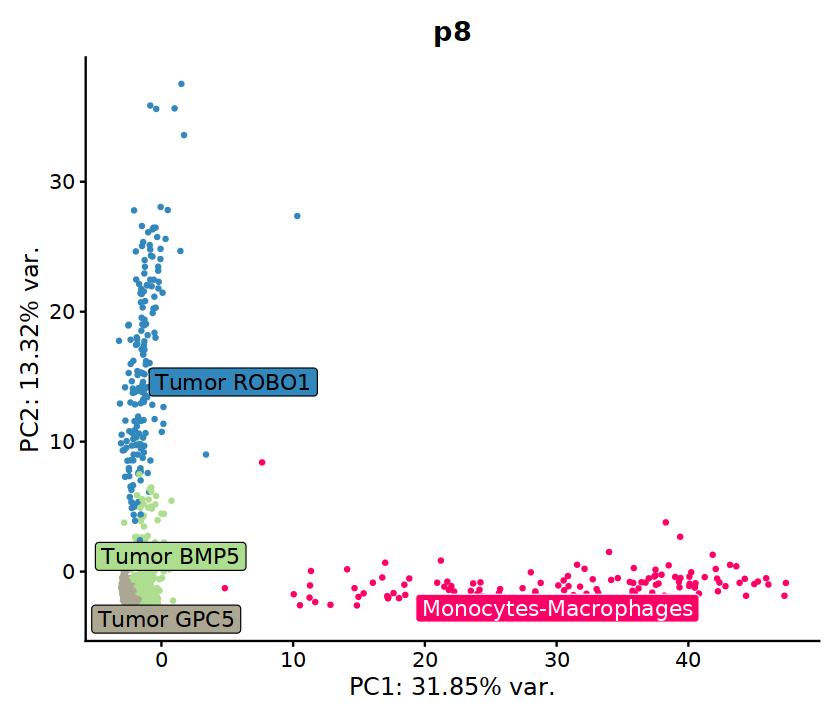

In [49]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

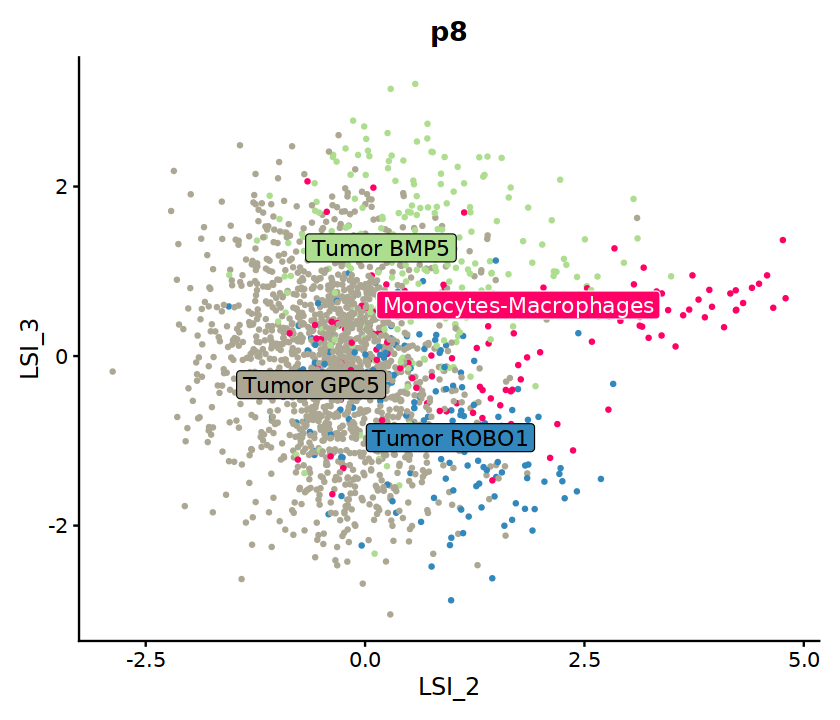

In [50]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

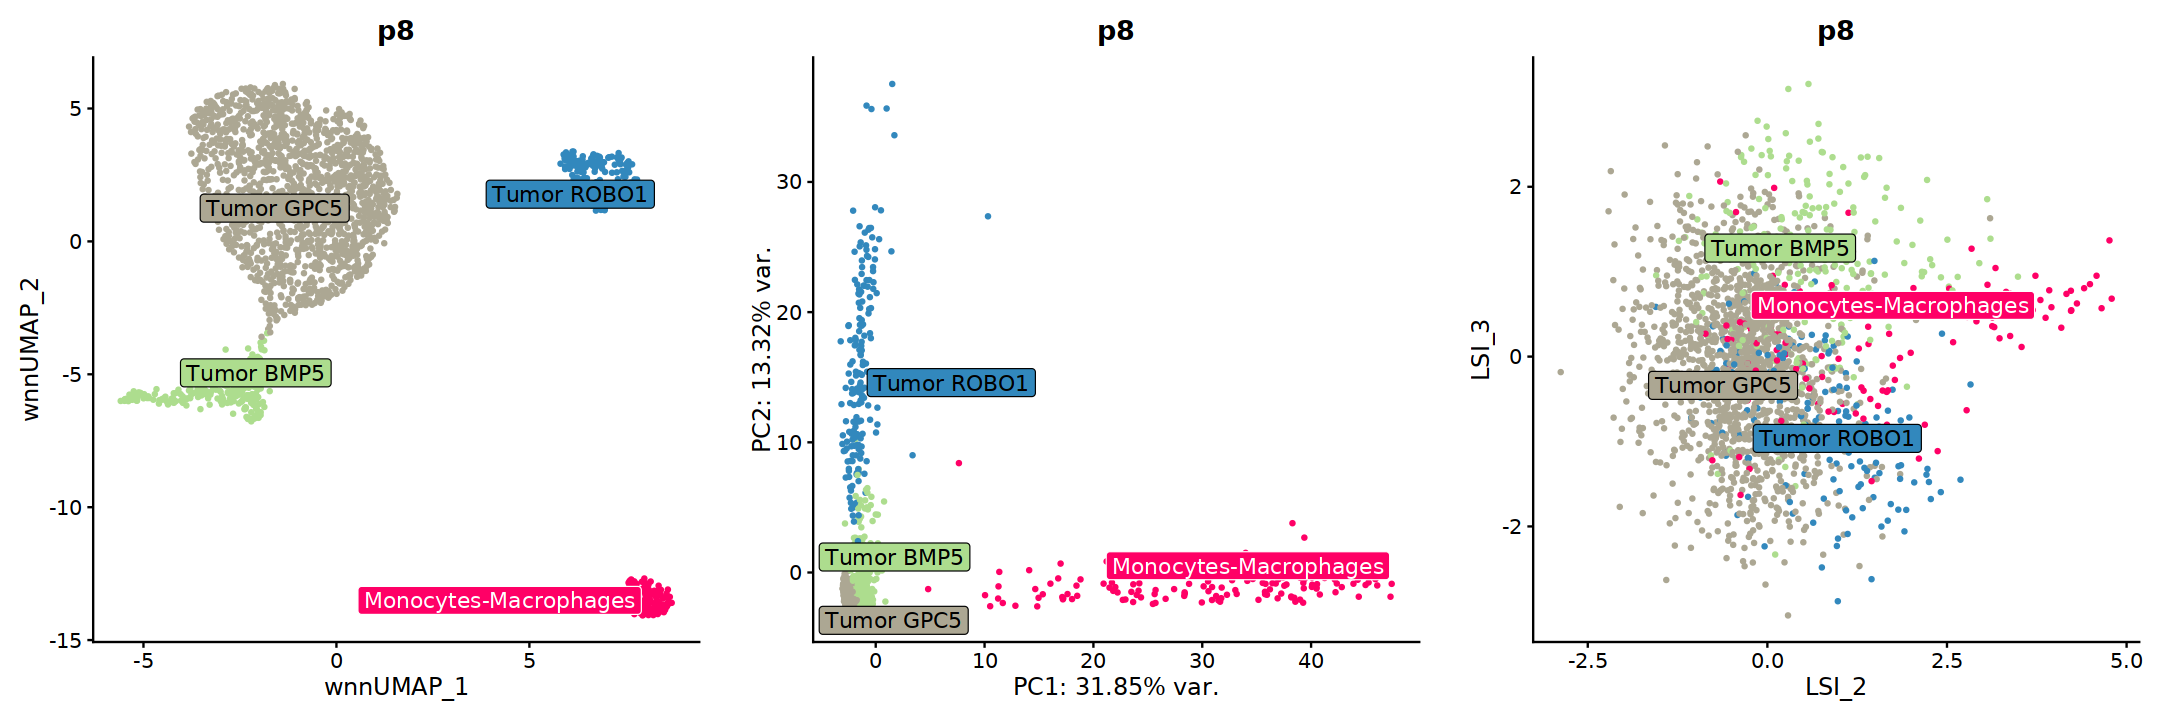

In [51]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [52]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [53]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("FABP7", "GLI2","MEIS2"), markers) ## common markers to all clusters

In [54]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

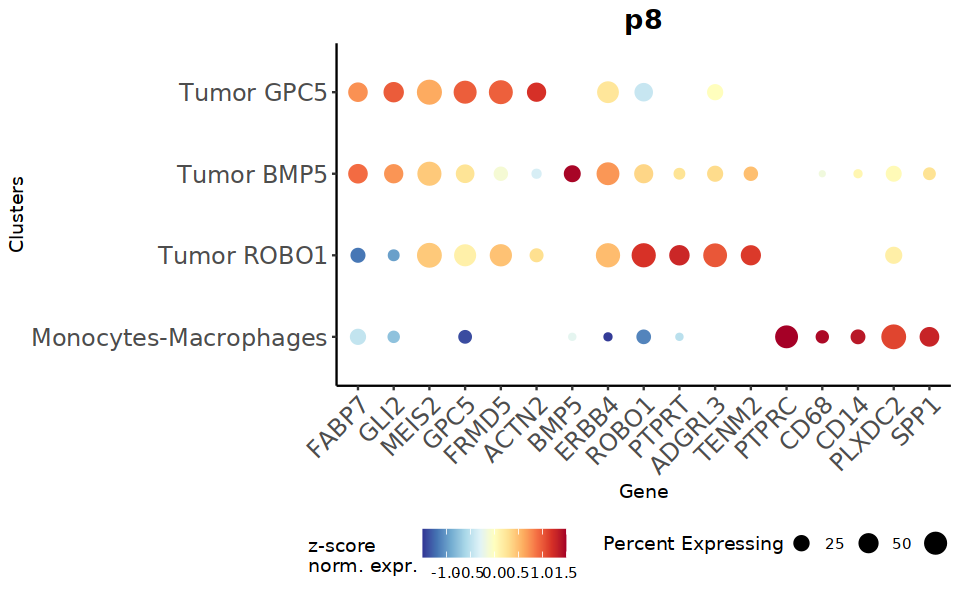

In [55]:
options(repr.plot.width = 8, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

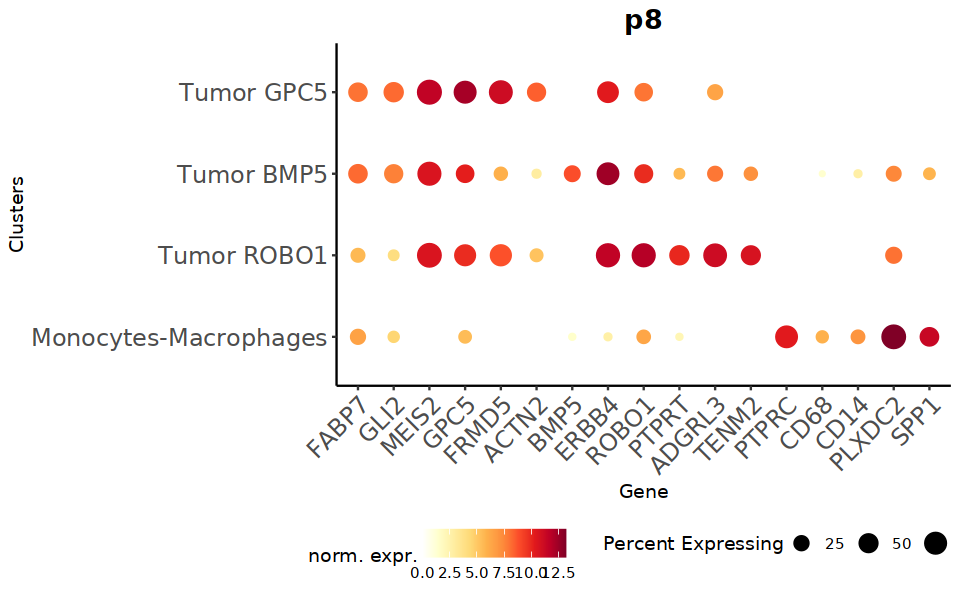

In [56]:
options(repr.plot.width = 8, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [57]:
ggsave(plot = dp1, width = 8, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [58]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [59]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [60]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [61]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    